# German Credit: Consolidated Project Analysis
**MSCS-634 | Deliverable 4, Part 1 | Fall 2026**  
**Team:** Minh Le, Sebastian Capkovi, Shreyas More, Elkana Munganga

This notebook integrates Deliverables 1–3 into a single executable workflow. It preserves the original methods and adds verified data alignment, fold-specific preprocessing, baseline comparisons, regenerated figures, and a computed summary.

## Project steps
1. Load, clean, and verify all shared attributes and outcome labels.
2. Explore distributions, missingness, correlations, and class balance.
3. Engineer features and compare regression models, including a log-target experiment.
4. Compare risk classifiers with stratified cross-validation and minority-class metrics.
5. Explore clustering and association rules.
6. Audit subgroup errors and synthesize findings, limitations, and recommendations.

Install `requirements.txt`, select that environment in Jupyter, and **Run All** from this folder. Inputs are local. The earlier deliverables are linked in the references. The later written report, slides, and recorded presentation are outside this part's scope.

In [1]:
from pathlib import Path
import json, sys, platform, importlib.metadata, time, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, accuracy_score,
 precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
 RocCurveDisplay, ConfusionMatrixDisplay, confusion_matrix, silhouette_score, adjusted_rand_score)
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

ROOT=Path.cwd()
if not (ROOT/'data').exists(): ROOT=ROOT/'MSCS_634_Project'
DATA, FIGURES, RESULTS=[ROOT/p for p in ['data','figures','results']]
for p in [FIGURES,RESULTS]: p.mkdir(exist_ok=True)
SEED=42
sns.set_theme(style='whitegrid',palette='colorblind')
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':160})
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES/f'{name}.png',bbox_inches='tight')
    plt.show()
    plt.close()
def table(frame,name):
    frame.to_csv(RESULTS/f'{name}.csv',index=False)
    display(frame.round(4))
def markdown_table(frame):
    f=frame.copy()
    for c in f.select_dtypes(include='number'): f[c]=f[c].map(lambda v:f'{v:.4f}')
    return '| '+' | '.join(f.columns)+' |\n|'+'|'.join(['---']*len(f.columns))+'|\n'+'\n'.join('| '+' | '.join(map(str,r))+' |' for r in f.itertuples(index=False,name=None))
versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','matplotlib','seaborn','scikit-learn','scipy','mlxtend','nbformat','nbclient']}
(RESULTS/'environment.json').write_text(json.dumps({'python':sys.version,'platform':platform.platform(),'packages':versions},indent=2))
print('Seed:',SEED,'Package versions:',versions)

Seed: 42 Package versions: {'numpy': '2.5.5', 'pandas': '3.1.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'mlxtend': '0.25.0', 'nbformat': '5.11.1', 'nbclient': '0.11.0'}


## 1. Dataset and preparation
The Kaggle German Credit derivative contains 1,000 historical applicants and nine predictors. Its manageable size, interpretable variables, and mixed numeric/categorical types support all project tasks. Amounts are historical Deutsche Mark (DM), not current dollars.

The [UCI Statlog original](https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data) has 20 predictors and a good/bad risk label. We retain the nine-variable project scope. The labels are benchmark risk classes, not a documented modern default event with a known time horizon.

Sources: [Deliverable 1](https://github.com/elkana-m/CS-634/tree/main/project1), [Deliverable 2](https://github.com/sebcap7/MSCS_634_ProjectDeliverable_2), [Deliverable 3](https://github.com/smore38997/MSCS_634_ProjectDeliverable_3). The references identify the original project repositories.

Remove the index, retain missing categories as `Unknown`, trim whitespace, check duplicates and numeric validity, and retain legitimate extreme loans. Verify **all nine shared attributes** against the UCI codes before attaching row-position risk labels. A matching class count alone would not verify alignment.

In [2]:
raw=pd.read_csv(DATA/'german_credit_data.csv').drop(columns=['Unnamed: 0'],errors='ignore')
cat_cols=['Sex','Housing','Saving accounts','Checking account','Purpose']
num_cols=['Age','Job','Credit amount','Duration']
missing=raw.isna().sum().rename('Missing').to_frame()
missing['Percent']=100*missing['Missing']/len(raw)
table(missing.reset_index(names='Feature'),'missingness')
clean=raw.copy()
for col in cat_cols: clean[col]=clean[col].fillna('Unknown').str.strip()
duplicate_count=int(clean.duplicated().sum())
# Do not silently drop records and invalidate row-position label alignment.
assert duplicate_count==0, 'Resolve duplicate alignment before proceeding.'
assert clean[['Age','Credit amount','Duration']].gt(0).all().all()
assert clean['Job'].isin([0,1,2,3]).all() and not clean.isna().any().any()
pd.testing.assert_frame_equal(clean,pd.read_csv(DATA/'german_credit_cleaned.csv'),check_dtype=False)
uci=pd.read_csv(DATA/'german.data',sep=r'\s+',header=None)
assert uci.shape==(1000,21)
reconstructed=pd.DataFrame({
 'Age':uci[12],'Sex':uci[8].map({'A91':'male','A92':'female','A93':'male','A94':'male','A95':'female'}),
 'Job':uci[16].map({'A171':0,'A172':1,'A173':2,'A174':3}),
 'Housing':uci[14].map({'A151':'rent','A152':'own','A153':'free'}),
 'Saving accounts':uci[5].map({'A61':'little','A62':'moderate','A63':'quite rich','A64':'rich','A65':'Unknown'}),
 'Checking account':uci[0].map({'A11':'little','A12':'moderate','A13':'rich','A14':'Unknown'}),
 'Credit amount':uci[4],'Duration':uci[1],
 'Purpose':uci[3].map({'A40':'car','A41':'car','A42':'furniture/equipment','A43':'radio/TV',
 'A44':'domestic appliances','A45':'repairs','A46':'education','A47':'vacation/others',
 'A48':'education','A49':'business','A410':'vacation/others'})})
pd.testing.assert_frame_equal(clean,reconstructed[clean.columns],check_dtype=False)
df=clean.assign(Risk=uci[20].map({1:'good',2:'bad'}))
pd.testing.assert_frame_equal(df,pd.read_csv(DATA/'german_credit_with_risk.csv'),check_dtype=False)
assert df['Risk'].value_counts().to_dict()=={'good':700,'bad':300}
df.to_csv(RESULTS/'verified_credit_data.csv',index=False)
print('Verified 1,000 rows, nine attributes, and all risk labels. Duplicates:',duplicate_count)
display(df.head())

,Feature,Missing,Percent
0,Age,0,0.0
1,Sex,0,0.0
2,Job,0,0.0
3,Housing,0,0.0
4,Saving accounts,183,18.3
5,Checking account,394,39.4
6,Credit amount,0,0.0
7,Duration,0,0.0
8,Purpose,0,0.0


Verified 1,000 rows, nine attributes, and all risk labels. Duplicates: 0


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,Unknown,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,Unknown,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


## 2. Exploratory analysis
**Semantic correction:** `Unknown` checking maps to UCI A14, **no checking account**; `Unknown` savings maps to A65, **unknown/no savings account**. Neither implies wealth or an established account. Checking `little` represents a negative balance. Original labels are retained for compatibility.

EDA uses the full sample descriptively. Prior deliverables already examined these benchmark test rows, so this is not a newly blinded external validation. Model searches below nevertheless isolate learned preprocessing within training folds.

,Statistic,Age,Job,Credit amount,Duration
0,count,1000.0000,1000.0000,1000.0000,1000.0000
1,mean,35.5460,1.9040,3271.2580,20.9030
2,std,11.3755,0.6536,2822.7369,12.0588
3,min,19.0000,0.0000,250.0000,4.0000
4,25%,27.0000,2.0000,1365.5000,12.0000
5,50%,33.0000,2.0000,2319.5000,18.0000
6,75%,42.0000,2.0000,3972.2500,24.0000
7,max,75.0000,3.0000,18424.0000,72.0000


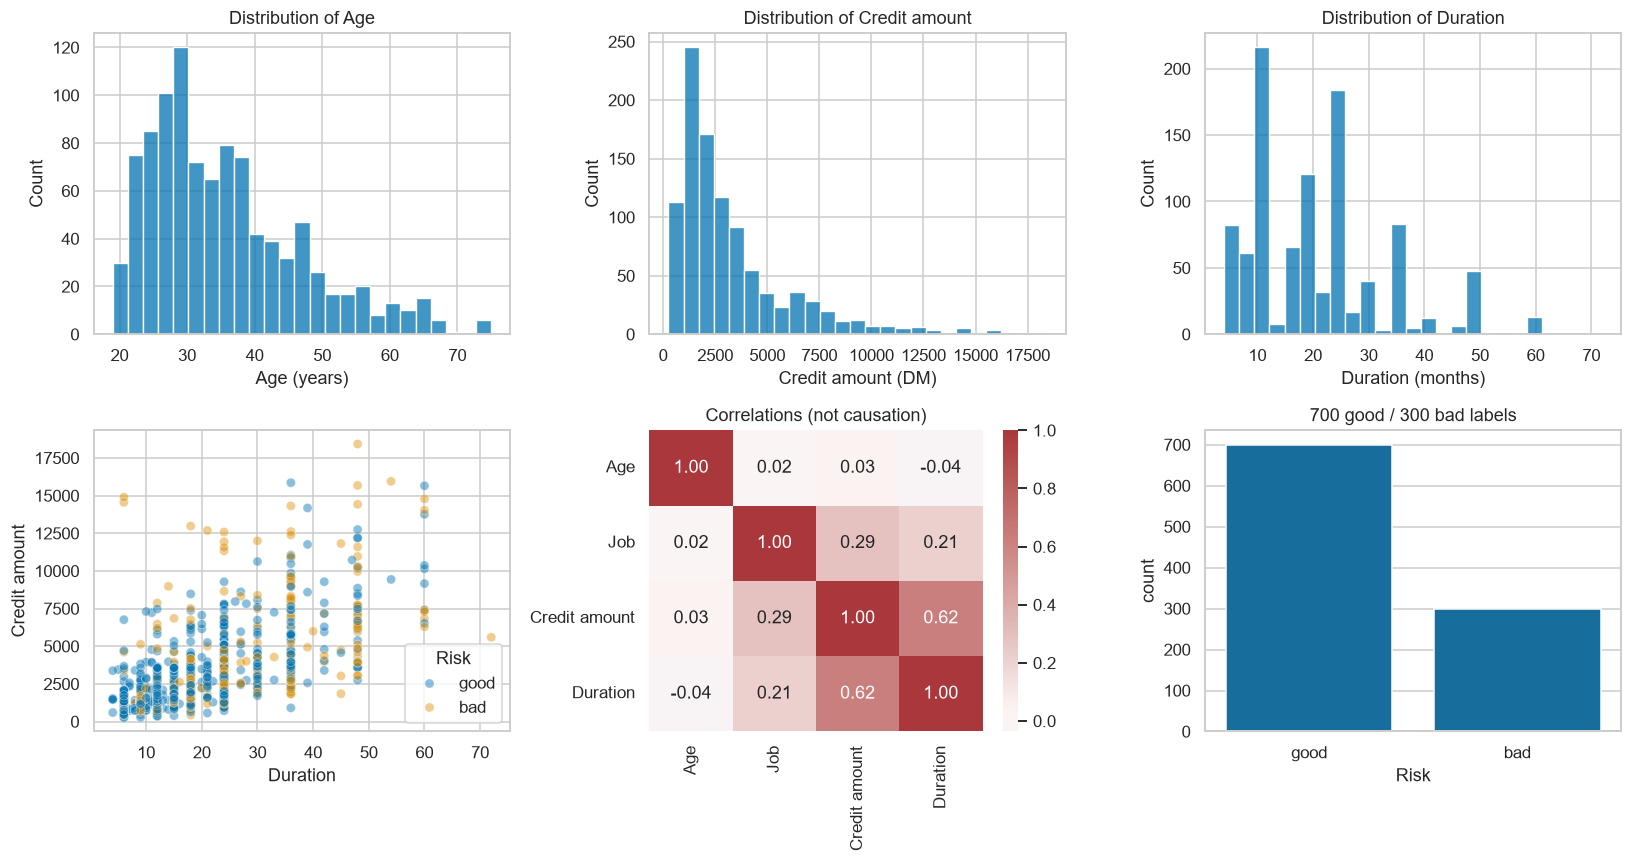

C:\Min\Codex\Residency\MSCS_634_Project\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


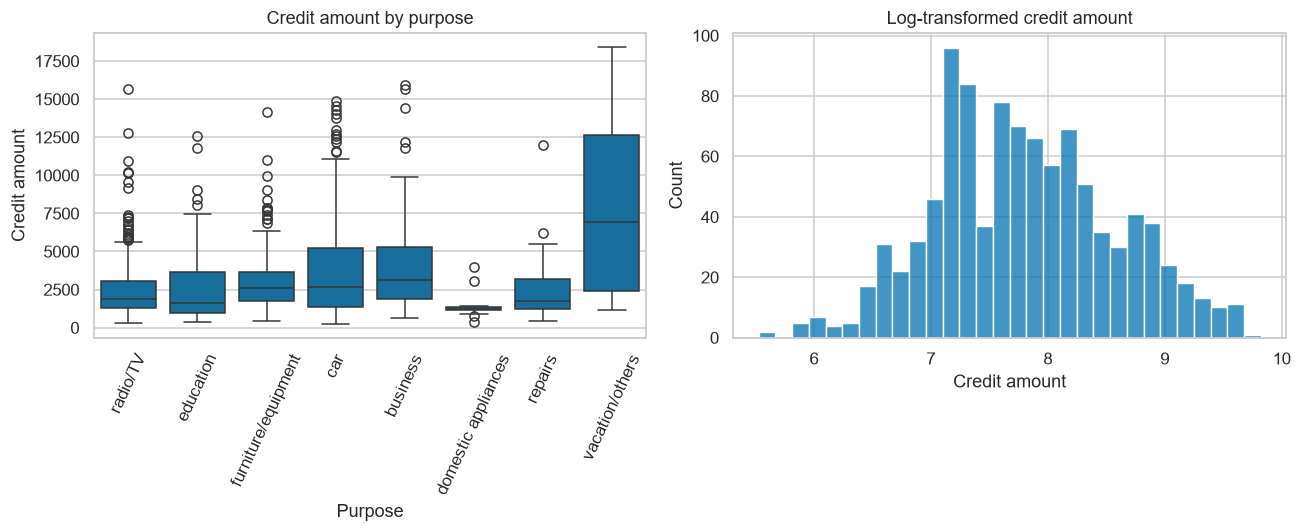

**EDA:** Mean amount 3,271.3 DM; skewness 1.95, versus 0.13 on the log scale. Duration–amount correlation is 0.625. An all-good classifier already achieves 70% accuracy.

In [3]:
table(clean[num_cols].describe().reset_index(names='Statistic'),'descriptive_statistics')
fig,axes=plt.subplots(2,3,figsize=(15,8))
for col,ax in zip(['Age','Credit amount','Duration'],axes[0]):
    sns.histplot(df[col],bins=25,ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col+(' (DM)' if col=='Credit amount' else ' (months)' if col=='Duration' else ' (years)'))
sns.scatterplot(data=df,x='Duration',y='Credit amount',hue='Risk',alpha=.45,ax=axes[1,0])
sns.heatmap(df[num_cols].corr(),annot=True,fmt='.2f',cmap='vlag',center=0,ax=axes[1,1])
axes[1,1].set_title('Correlations (not causation)')
sns.countplot(data=df,x='Risk',order=['good','bad'],ax=axes[1,2])
axes[1,2].set_title('700 good / 300 bad labels')
savefig('01_eda_overview')
fig,axes=plt.subplots(1,2,figsize=(12,5))
sns.boxplot(data=df,x='Purpose',y='Credit amount',ax=axes[0])
axes[0].tick_params(axis='x',rotation=65)
axes[0].set_title('Credit amount by purpose')
sns.histplot(np.log1p(df['Credit amount']),bins=30,ax=axes[1])
axes[1].set_title('Log-transformed credit amount')
savefig('02_eda_purpose_and_log')
correlation=df['Duration'].corr(df['Credit amount'])
display(Markdown(f"**EDA:** Mean amount {df['Credit amount'].mean():,.1f} DM; skewness {df['Credit amount'].skew():.2f}, versus {np.log1p(df['Credit amount']).skew():.2f} on the log scale. Duration–amount correlation is {correlation:.3f}. An all-good classifier already achieves 70% accuracy."))

## 3. Regression and feature engineering
Retain Linear Regression, Ridge, Lasso, Elastic Net, and the log-target experiment; add a mean-prediction baseline. `Duration_sq`, `Age_sq`, and `Duration_x_Job` capture curvature and interaction without using the target. Numeric Job assumes equally spaced skill codes.

Use an 80/20 split, seed 42, and five-fold CV. **GridSearchCV wraps the entire pipeline**, fitting encoding and scaling inside each fold, including penalty selection. Regression standardizes encoded features as well as numeric terms. Explicit alpha grids replace automatic searches, so results may differ from Deliverable 2. Both target transformations are scored on original-scale RMSE. Select on training CV before test evaluation. CV tuning scores are not nested-CV estimates; test rows were previously inspected in earlier deliverables.

In [4]:
reg_X=clean.drop(columns='Credit amount').copy()
reg_X['Duration_sq']=reg_X['Duration']**2
reg_X['Age_sq']=reg_X['Age']**2
reg_X['Duration_x_Job']=reg_X['Duration']*reg_X['Job']
rx_train,rx_test,ry_train,ry_test=train_test_split(reg_X,clean['Credit amount'],test_size=.2,random_state=SEED)
reg_num=['Age','Job','Duration','Duration_sq','Age_sq','Duration_x_Job']
def reg_pipeline(model):
    encoder=ColumnTransformer([('num','passthrough',reg_num),
     ('cat',OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False),cat_cols)])
    return Pipeline([('encode',encoder),('scale',StandardScaler()),('model',model)])
reg_cv=KFold(5,shuffle=True,random_state=SEED)
reg_specs={'Mean baseline':(DummyRegressor(),{}),'Linear Regression':(LinearRegression(),{}),
 'Ridge':(Ridge(),{'model__alpha':np.logspace(-2,3,20)}),
 'Lasso':(Lasso(max_iter=100000),{'model__alpha':np.logspace(-1,3,20)}),
 'Elastic Net':(ElasticNet(max_iter=100000),{'model__alpha':np.logspace(-2,2,12),'model__l1_ratio':[.1,.5,.9,.95]})}
reg_searches={}
for scale in ['original','log1p']:
    for name,(model,grid) in reg_specs.items():
        if scale=='log1p' and name=='Mean baseline': continue
        estimator=reg_pipeline(clone(model))
        if scale=='log1p':
            estimator=TransformedTargetRegressor(regressor=estimator,func=np.log1p,inverse_func=np.expm1)
            grid={'regressor__'+k:v for k,v in grid.items()}
        search=GridSearchCV(estimator,grid,scoring={'rmse':'neg_root_mean_squared_error','r2':'r2'},refit='rmse',cv=reg_cv,n_jobs=2,error_score='raise')
        search.fit(rx_train,ry_train)
        reg_searches[f'{name} ({scale})']=search
# Freeze model selection before computing held-out metrics.
selected_reg=max(reg_searches,key=lambda n:reg_searches[n].best_score_)
reg_rows,reg_predictions=[],{}
for name,search in reg_searches.items():
    pred=search.predict(rx_test)
    reg_predictions[name]=pred
    idx=search.best_index_
    reg_rows.append({'Model':name,'CV RMSE':-search.best_score_,'CV RMSE SD':search.cv_results_['std_test_rmse'][idx],
     'CV R2':search.cv_results_['mean_test_r2'][idx],'Train R2':r2_score(ry_train,search.predict(rx_train)),
     'Test R2':r2_score(ry_test,pred),'Test MSE':mean_squared_error(ry_test,pred),
     'Test RMSE':np.sqrt(mean_squared_error(ry_test,pred)),'Test MAE':mean_absolute_error(ry_test,pred)})
reg_results=pd.DataFrame(reg_rows)
table(reg_results,'regression_metrics')
print('Selected on CV RMSE:',selected_reg,reg_searches[selected_reg].best_params_)
(RESULTS/'regression_parameters.json').write_text(json.dumps({n:s.best_params_ for n,s in reg_searches.items()},indent=2,default=float))

,Model,CV RMSE,CV RMSE SD,CV R2,Train R2,Test R2,Test MSE,Test RMSE,Test MAE
0,Mean baseline (original),2883.3089,323.8075,-0.0113,0.0000,-0.0328,6.283632e+06,2506.7173,1903.8873
1,Linear Regression (original),2128.0199,262.5984,0.4404,0.5024,0.3192,4.142279e+06,2035.2590,1385.6462
2,Ridge (original),2102.4168,263.4386,0.4557,0.4998,0.3559,3.918441e+06,1979.5054,1361.1132
3,Lasso (original),2110.3270,264.0791,0.4502,0.5009,0.3395,4.018766e+06,2004.6860,1366.2302
4,Elastic Net (original),2102.1741,262.0026,0.4561,0.4976,0.3689,3.839417e+06,1959.4430,1351.3798
5,Linear Regression (log1p),2209.8213,283.7568,0.3981,0.4542,0.3624,3.879357e+06,1969.6084,1235.4989
6,Ridge (log1p),2209.8476,283.7593,0.3981,0.4542,0.3623,3.879551e+06,1969.6575,1235.5149
7,Lasso (log1p),2328.6468,270.2306,0.3353,0.3526,0.3651,3.862545e+06,1965.3360,1255.8530
8,Elastic Net (log1p),2221.8677,286.7514,0.3905,0.4382,0.3096,4.200131e+06,2049.4220,1255.6860


Selected on CV RMSE: Elastic Net (original) {'model__alpha': np.float64(3.511191734215131), 'model__l1_ratio': 0.95}


575

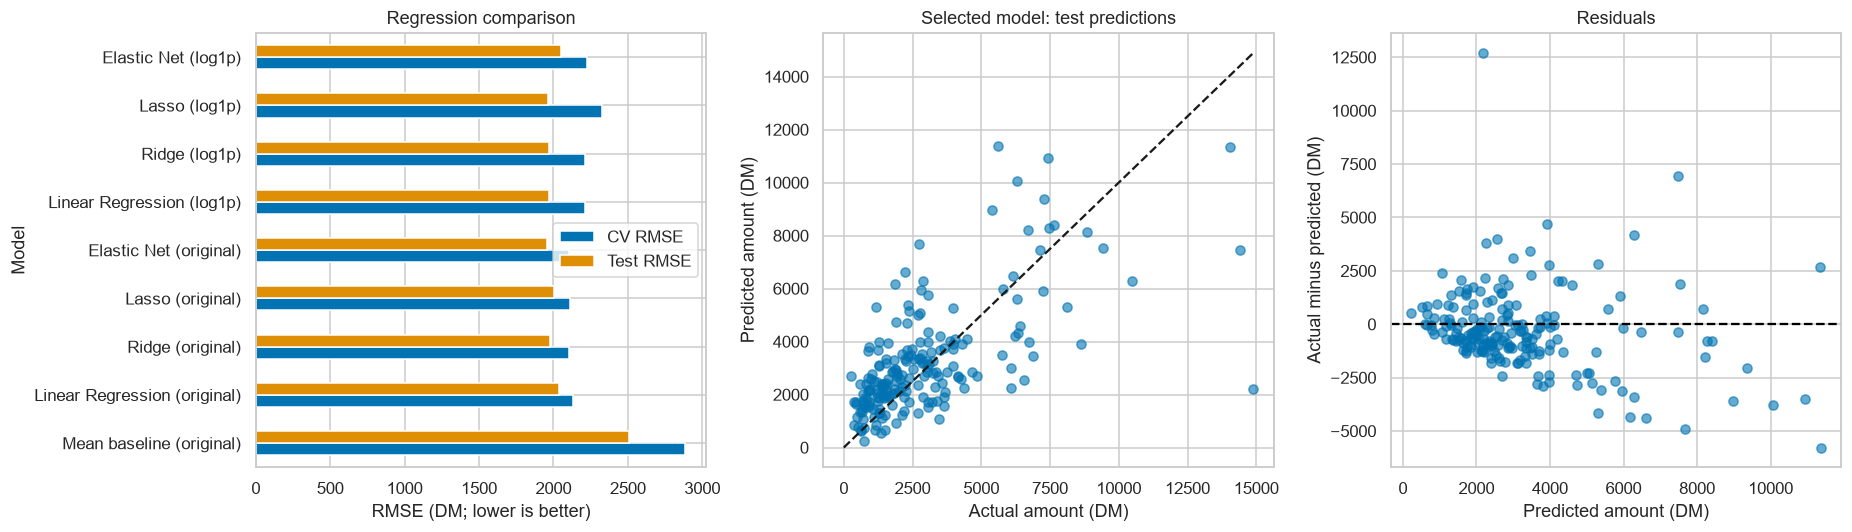

,Feature,RMSE increase,SD
8,Duration_sq,147.9063,50.3962
10,Duration_x_Job,94.9997,43.4438
7,Purpose,68.7239,16.3973
6,Duration,64.3455,36.7018
4,Saving accounts,6.8260,4.5163
2,Job,6.1684,6.1937
0,Age,1.0269,1.8683
9,Age_sq,0.6973,1.0032
1,Sex,-0.3398,4.1888
3,Housing,-17.1589,12.6115


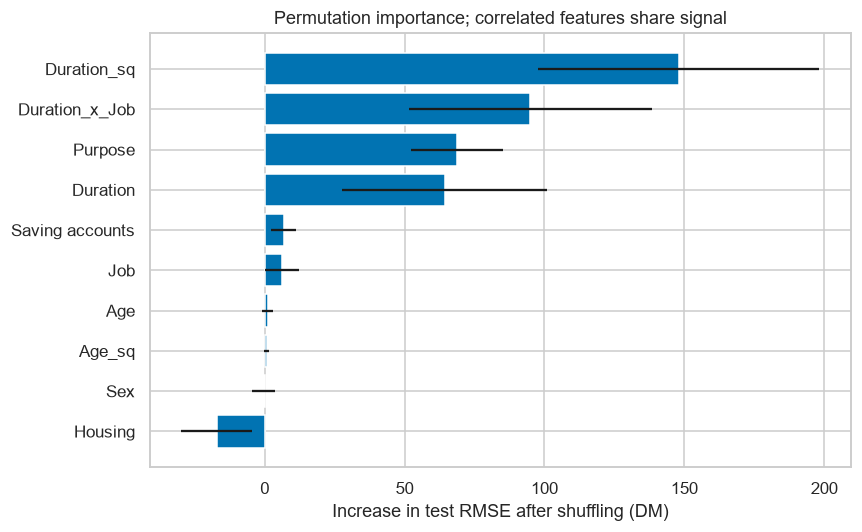

,Feature,Coefficient
0,num__Age,38.2937
1,num__Job,119.7254
2,num__Duration,488.4118
3,num__Duration_sq,630.4574
4,num__Age_sq,20.3749
5,num__Duration_x_Job,572.4167
6,cat__Sex_male,105.5756
7,cat__Housing_own,-220.9929
8,cat__Housing_rent,-40.8218
9,cat__Saving accounts_little,-100.0023


Loans above training 90th percentile: 10 ; mean actual-minus-predicted: 3507.7 DM


In [5]:
fig,axes=plt.subplots(1,3,figsize=(17,5))
reg_results.set_index('Model')[['CV RMSE','Test RMSE']].plot.barh(ax=axes[0])
axes[0].set(xlabel='RMSE (DM; lower is better)',title='Regression comparison')
pred=reg_predictions[selected_reg]
axes[1].scatter(ry_test,pred,alpha=.6)
lims=[0,max(ry_test.max(),pred.max())]
axes[1].plot(lims,lims,'k--')
axes[1].set(xlabel='Actual amount (DM)',ylabel='Predicted amount (DM)',title='Selected model: test predictions')
axes[2].scatter(pred,ry_test-pred,alpha=.6)
axes[2].axhline(0,color='black',linestyle='--')
axes[2].set(xlabel='Predicted amount (DM)',ylabel='Actual minus predicted (DM)',title='Residuals')
savefig('03_regression_evaluation')
imp=permutation_importance(reg_searches[selected_reg],rx_test,ry_test,scoring='neg_root_mean_squared_error',n_repeats=10,random_state=SEED,n_jobs=2)
importance=pd.DataFrame({'Feature':reg_X.columns,'RMSE increase':imp.importances_mean,'SD':imp.importances_std}).sort_values('RMSE increase',ascending=False)
table(importance,'regression_importance')
p=importance.head(10).sort_values('RMSE increase')
plt.figure(figsize=(8,5))
plt.barh(p['Feature'],p['RMSE increase'],xerr=p['SD'])
plt.xlabel('Increase in test RMSE after shuffling (DM)')
plt.title('Permutation importance; correlated features share signal')
savefig('04_regression_importance')
est=reg_searches[selected_reg].best_estimator_
pipe=est.regressor_ if hasattr(est,'regressor_') else est
if hasattr(pipe.named_steps['model'],'coef_'):
    table(pd.DataFrame({'Feature':pipe.named_steps['encode'].get_feature_names_out(),'Coefficient':pipe.named_steps['model'].coef_}),'selected_regression_coefficients')
large=ry_test>=ry_train.quantile(.9)
print('Loans above training 90th percentile:',int(large.sum()),'; mean actual-minus-predicted:',round((ry_test[large]-pred[large]).mean(),1),'DM')

## 4. Classification
Positive class = **bad (1)**; good = 0. Retain baseline/tuned trees, tuned k-NN, tuned random forest, and fixed balanced RBF SVM. Add a majority baseline. Stratified 80/20 splitting yields 140 good and 60 bad test labels.

Encoding and numeric scaling occur inside each stratified five-fold CV fit. Smaller explicit tree/forest grids keep this integrated workflow practical. Select on training CV AUC; evaluate accuracy, bad-class precision/recall/F1, weighted F1, ROC-AUC, and average precision. SVM decision scores are rankings, not calibrated probabilities. Predictions use default decision rules; no operational threshold or cost has been validated.

,Model,CV AUC,CV AUC SD,Accuracy,Bad precision,Bad recall,Bad F1,Weighted F1,Test AUC,Average precision
0,Majority baseline,0.5000,0.0000,0.700,0.0000,0.0000,0.0000,0.5765,0.5000,0.3000
1,Baseline tree,0.5756,0.0572,0.665,0.4386,0.4167,0.4274,0.6625,0.5940,0.3577
2,Tuned tree,0.7056,0.0479,0.725,0.5556,0.4167,0.4762,0.7123,0.7602,0.5663
3,Tuned k-NN,0.7207,0.0322,0.735,0.6667,0.2333,0.3457,0.6874,0.7612,0.6314
4,Tuned random forest,0.7578,0.0552,0.750,0.7273,0.2667,0.3902,0.7070,0.7737,0.6175
5,Balanced SVM,0.7444,0.0425,0.715,0.5169,0.7667,0.6174,0.7263,0.7990,0.6595


Selected on CV AUC: Tuned random forest


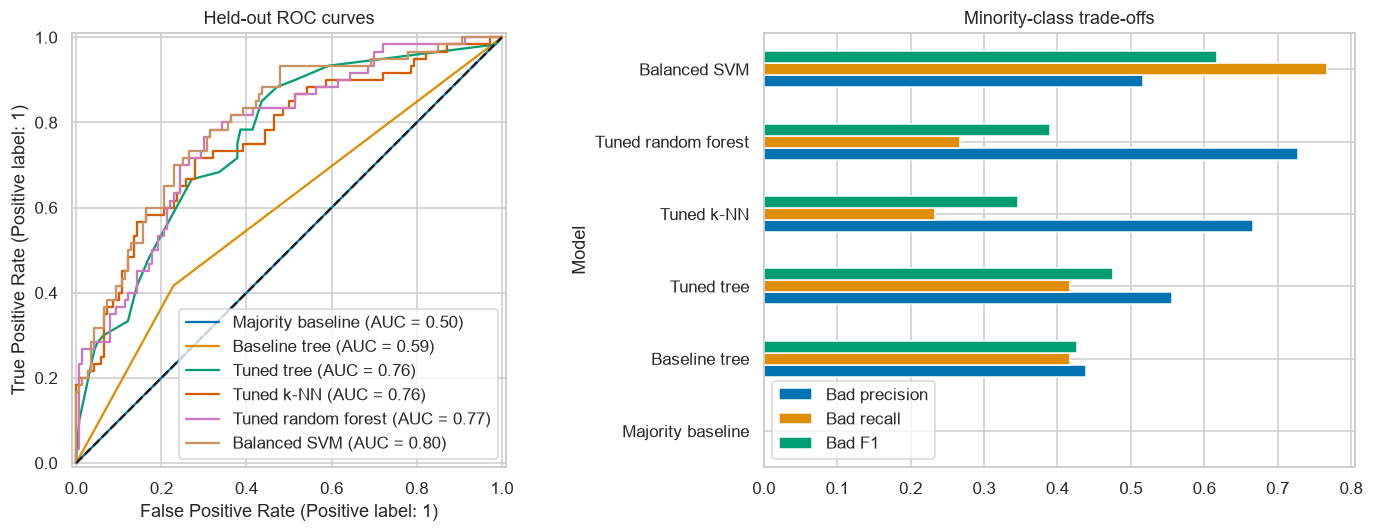

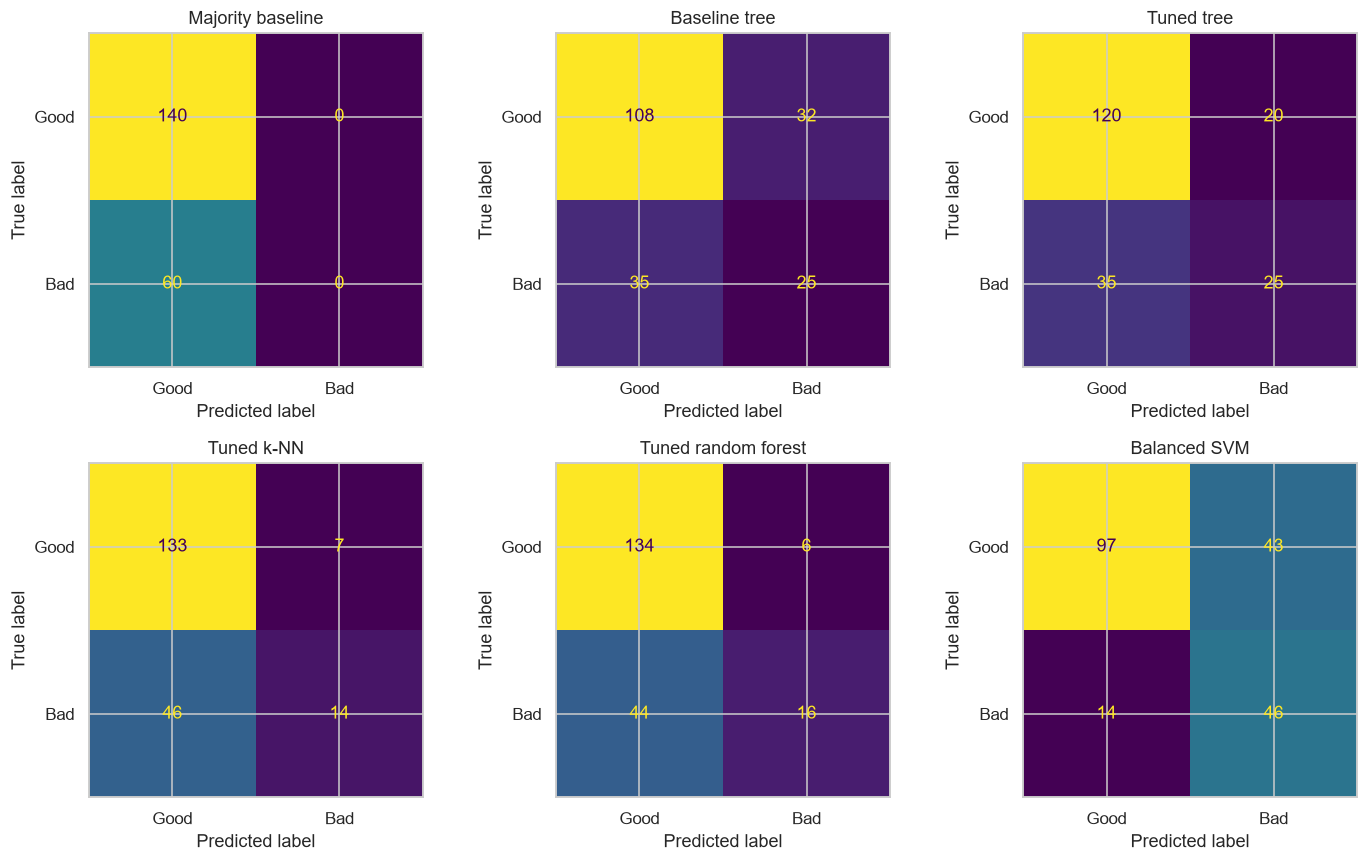

In [6]:
X=clean.copy()
y=df['Risk'].eq('bad').astype(int)
cx_train,cx_test,cy_train,cy_test=train_test_split(X,y,test_size=.2,random_state=SEED,stratify=y)
def class_preprocessor():
    return ColumnTransformer([('num',StandardScaler(),num_cols),
     ('cat',OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False),cat_cols)])
class_cv=StratifiedKFold(5,shuffle=True,random_state=SEED)
class_specs={
 'Majority baseline':(DummyClassifier(strategy='most_frequent'),{}),
 'Baseline tree':(DecisionTreeClassifier(random_state=SEED),{}),
 'Tuned tree':(DecisionTreeClassifier(random_state=SEED),{'model__max_depth':[3,5,8,None],
  'model__min_samples_leaf':[2,8],'model__min_samples_split':[2,20],'model__class_weight':[None,'balanced']}),
 'Tuned k-NN':(KNeighborsClassifier(),{'model__n_neighbors':[5,11,21],'model__weights':['uniform','distance'],'model__metric':['euclidean','manhattan']}),
 'Tuned random forest':(RandomForestClassifier(n_estimators=100,random_state=SEED,n_jobs=1),
  {'model__max_depth':[4,6,None],'model__min_samples_leaf':[2,4,8],'model__class_weight':[None,'balanced']}),
 'Balanced SVM':(SVC(kernel='rbf',class_weight='balanced',random_state=SEED),{})}
class_searches={}
for name,(model,grid) in class_specs.items():
    search=GridSearchCV(Pipeline([('prepare',class_preprocessor()),('model',model)]),grid,scoring='roc_auc',cv=class_cv,n_jobs=2,error_score='raise')
    search.fit(cx_train,cy_train)
    class_searches[name]=search
selected_class=max(class_searches,key=lambda n:class_searches[n].best_score_)
class_rows,class_predictions,class_scores=[],{},{}
for name,search in class_searches.items():
    pred=search.predict(cx_test)
    score=search.decision_function(cx_test) if hasattr(search,'decision_function') else search.predict_proba(cx_test)[:,1]
    class_predictions[name],class_scores[name]=pred,score
    class_rows.append({'Model':name,'CV AUC':search.best_score_,'CV AUC SD':search.cv_results_['std_test_score'][search.best_index_],
     'Accuracy':accuracy_score(cy_test,pred),'Bad precision':precision_score(cy_test,pred,zero_division=0),
     'Bad recall':recall_score(cy_test,pred),'Bad F1':f1_score(cy_test,pred),'Weighted F1':f1_score(cy_test,pred,average='weighted'),
     'Test AUC':roc_auc_score(cy_test,score),'Average precision':average_precision_score(cy_test,score)})
class_results=pd.DataFrame(class_rows)
table(class_results,'classification_metrics')
print('Selected on CV AUC:',selected_class)
(RESULTS/'classification_parameters.json').write_text(json.dumps({n:s.best_params_ for n,s in class_searches.items()},indent=2))
fig,axes=plt.subplots(1,2,figsize=(13,5))
for name,score in class_scores.items(): RocCurveDisplay.from_predictions(cy_test,score,name=name,ax=axes[0])
axes[0].plot([0,1],[0,1],'k--')
axes[0].set_title('Held-out ROC curves')
class_results.set_index('Model')[['Bad precision','Bad recall','Bad F1']].plot.barh(ax=axes[1])
axes[1].set_title('Minority-class trade-offs')
savefig('05_classification_performance')
fig,axes=plt.subplots(2,3,figsize=(13,8))
for ax,(name,pred) in zip(axes.flat,class_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(cy_test,pred,display_labels=['Good','Bad'],colorbar=False,ax=ax)
    ax.set_title(name)
savefig('06_confusion_matrices')

## 5. Clustering
Cluster all applicants **without Risk**, adding risk labels only afterward for profiling. Full-sample preprocessing is appropriate for this descriptive task. Euclidean distance on mixed data and numeric Job are assumptions.

Compare k=2…8 using inertia and silhouette; retain k=3 for continuity but report the actual silhouette winner. Compare K-Means and Ward clustering using adjusted Rand index (ARI). The dendrogram uses all 1,000 rows rather than the earlier first-80-row illustration. PCA is a lossy visualization, not the clustering space.

,k,Inertia,Silhouette
0,2,4926.5880,0.2407
1,3,4330.3650,0.1684
2,4,3918.0495,0.1635
3,5,3706.2572,0.1314
4,6,3542.8561,0.1234
5,7,3386.0491,0.1273
6,8,3280.4764,0.1066


,Cluster,Applicants,Age,Credit_amount,Duration,Job,Bad_rate
0,0,562,29.2295,2195.7295,17.2064,1.8754,0.2900
1,1,192,35.0365,7631.6042,38.5990,2.2917,0.4635
2,2,246,50.3740,2325.1626,15.5366,1.6667,0.1951


Best silhouette k: 2 ; K-Means/hierarchical ARI: 0.408


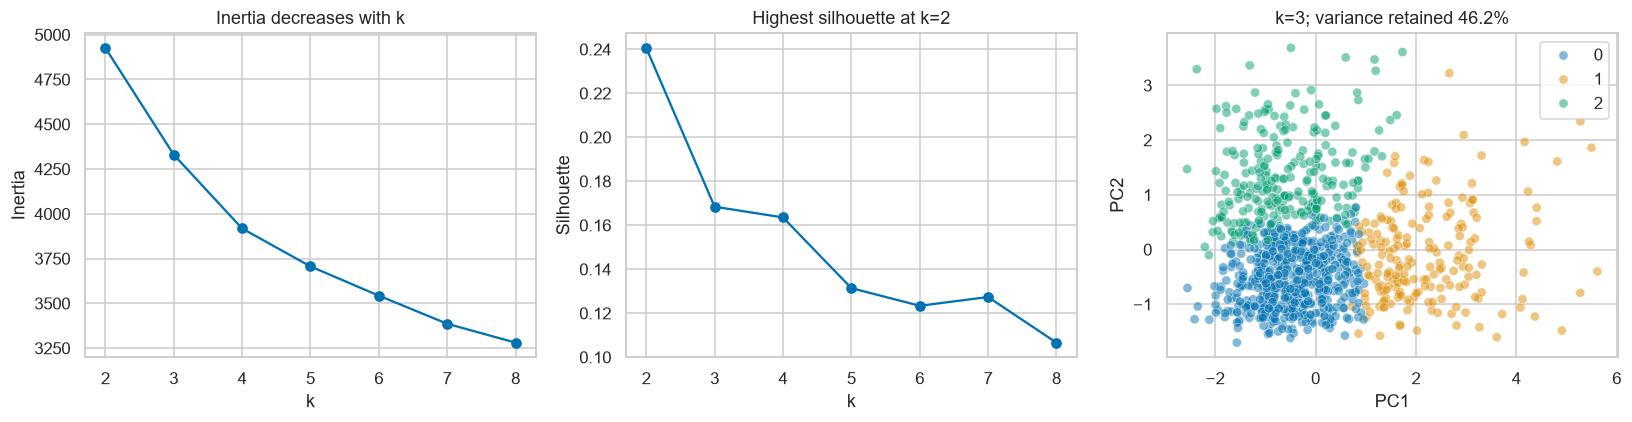

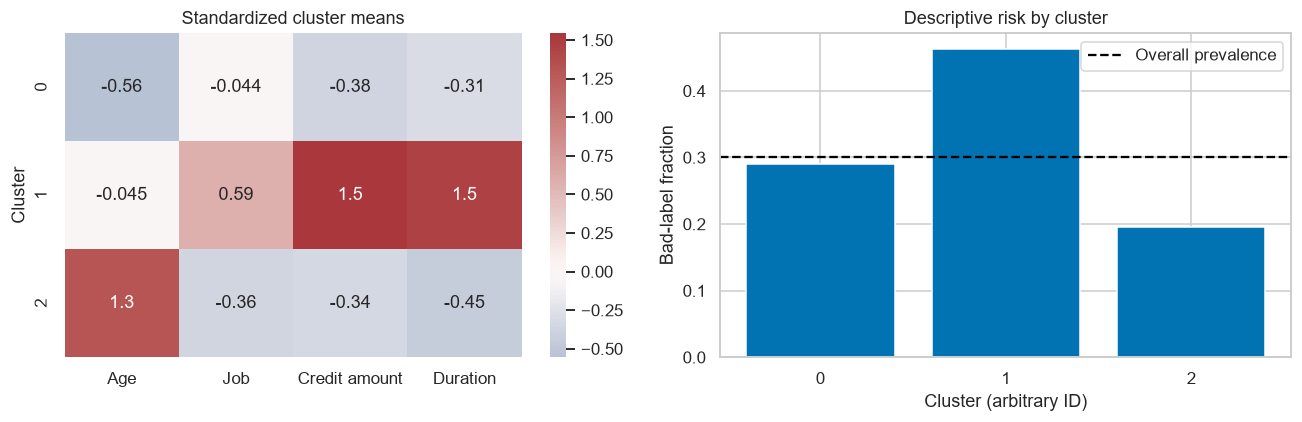

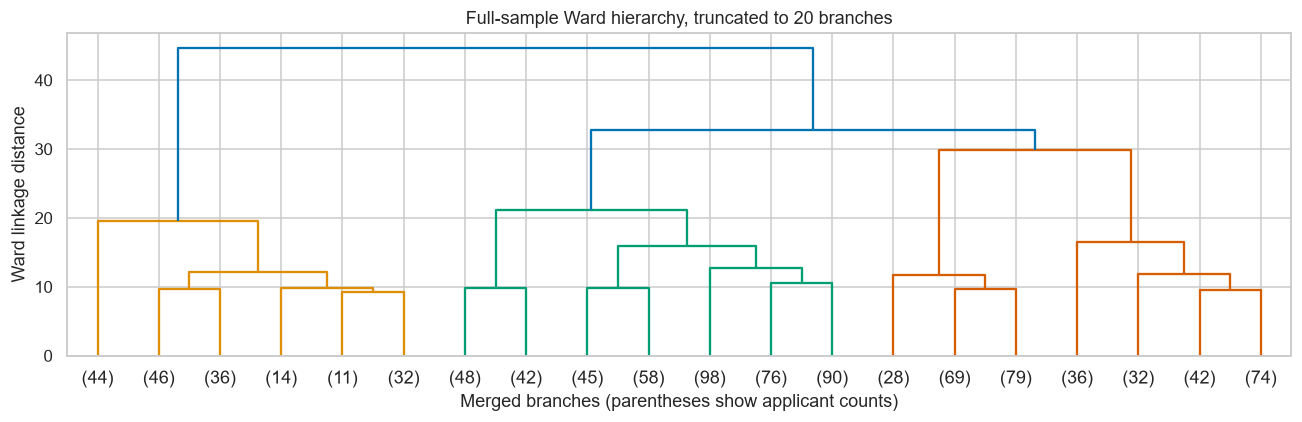

In [7]:
cluster_X=class_preprocessor().fit_transform(X)
cluster_models,cluster_rows={},[]
for k in range(2,9):
    km=KMeans(n_clusters=k,random_state=SEED,n_init=10).fit(cluster_X)
    cluster_models[k]=km
    cluster_rows.append({'k':k,'Inertia':km.inertia_,'Silhouette':silhouette_score(cluster_X,km.labels_)})
cluster_results=pd.DataFrame(cluster_rows)
table(cluster_results,'clustering_metrics')
best_k=int(cluster_results.loc[cluster_results['Silhouette'].idxmax(),'k'])
km=cluster_models[3]
profile_data=df.assign(Cluster=km.labels_,Bad=y)
profiles=profile_data.groupby('Cluster').agg(Applicants=('Bad','size'),Age=('Age','mean'),Credit_amount=('Credit amount','mean'),Duration=('Duration','mean'),Job=('Job','mean'),Bad_rate=('Bad','mean')).reset_index()
table(profiles,'cluster_profiles_k3')
agg_labels=AgglomerativeClustering(n_clusters=3,linkage='ward').fit_predict(cluster_X)
ari=adjusted_rand_score(km.labels_,agg_labels)
print('Best silhouette k:',best_k,'; K-Means/hierarchical ARI:',round(ari,3))
fig,axes=plt.subplots(1,3,figsize=(15,4))
axes[0].plot(cluster_results['k'],cluster_results['Inertia'],'o-')
axes[0].set(xlabel='k',ylabel='Inertia',title='Inertia decreases with k')
axes[1].plot(cluster_results['k'],cluster_results['Silhouette'],'o-')
axes[1].set(xlabel='k',ylabel='Silhouette',title=f'Highest silhouette at k={best_k}')
pca=PCA(n_components=2)
coords=pca.fit_transform(cluster_X)
sns.scatterplot(x=coords[:,0],y=coords[:,1],hue=km.labels_,palette='colorblind',alpha=.5,ax=axes[2])
axes[2].set(xlabel='PC1',ylabel='PC2',title=f'k=3; variance retained {pca.explained_variance_ratio_.sum():.1%}')
savefig('07_clustering_diagnostics')
fig,axes=plt.subplots(1,2,figsize=(12,4))
standard_profiles=profile_data.groupby('Cluster')[num_cols].mean().sub(clean[num_cols].mean()).div(clean[num_cols].std())
sns.heatmap(standard_profiles,annot=True,center=0,cmap='vlag',ax=axes[0])
axes[0].set_title('Standardized cluster means')
axes[1].bar(profiles['Cluster'].astype(str),profiles['Bad_rate'])
axes[1].axhline(.3,color='black',linestyle='--',label='Overall prevalence')
axes[1].set(xlabel='Cluster (arbitrary ID)',ylabel='Bad-label fraction',title='Descriptive risk by cluster')
axes[1].legend()
savefig('08_cluster_profiles')
plt.figure(figsize=(12,4))
dendrogram(linkage(cluster_X,method='ward'),truncate_mode='lastp',p=20,show_leaf_counts=True)
plt.title('Full-sample Ward hierarchy, truncated to 20 branches')
plt.xlabel('Merged branches (parentheses show applicant counts)')
plt.ylabel('Ward linkage distance')
savefig('09_hierarchical_dendrogram')

## 6. Association mining
Retain Deliverable 3's **credit quartiles**, correcting its README's inconsistent fixed thresholds. Print exact boundaries. Age bins are ≤25, 26–35, 36–50, >50; the earlier `<25` label incorrectly described a bin containing 25. Duration bins are ≤12, 13–24, >24 months.

Minimum support = 0.04 (40 applicants); lift ≥1.1. Support is joint prevalence, confidence is consequent prevalence among antecedent matches, and lift divides confidence by overall consequent prevalence. Verify that Apriori and FP-Growth agree on itemsets and support. Timings are single-run observations, not universal claims.

Rules use the full sample for exploration. They are not causal effects or validated forecasts. Overlapping rules and multiple comparisons require independent validation before policy use.

Credit quartile edges (DM): [  250.    1365.5   2319.5   3972.25 18424.  ] ; basket shape: (1000, 35)


,Antecedent,Joint count,Antecedent count,support,confidence,lift
1432,Checking account=little + Duration group=>24,42,64,0.042,0.6562,2.1875
1422,Checking account=little + Credit quartile=Q4,40,65,0.040,0.6154,2.0513
4718,Age group=26-35 + Checking account=little + Sa...,44,73,0.044,0.6027,2.0091
4818,Credit quartile=Q4 + Duration group=>24 + Savi...,52,89,0.052,0.5843,1.9476
1417,Age group=26-35 + Checking account=little,53,94,0.053,0.5638,1.8794
1200,Duration group=>24 + Saving accounts=little,76,136,0.076,0.5588,1.8627
1468,Checking account=moderate + Duration group=>24,44,80,0.044,0.5500,1.8333
2776,Duration group=>24 + Saving accounts=little + ...,55,101,0.055,0.5446,1.8152
4730,Checking account=little + Duration group=13-24...,48,90,0.048,0.5333,1.7778
231,Checking account=little + Sex=female,46,88,0.046,0.5227,1.7424


Both algorithms: 1520 itemsets; 7796 rules. Apriori 0.021s; FP-Growth 0.151s.


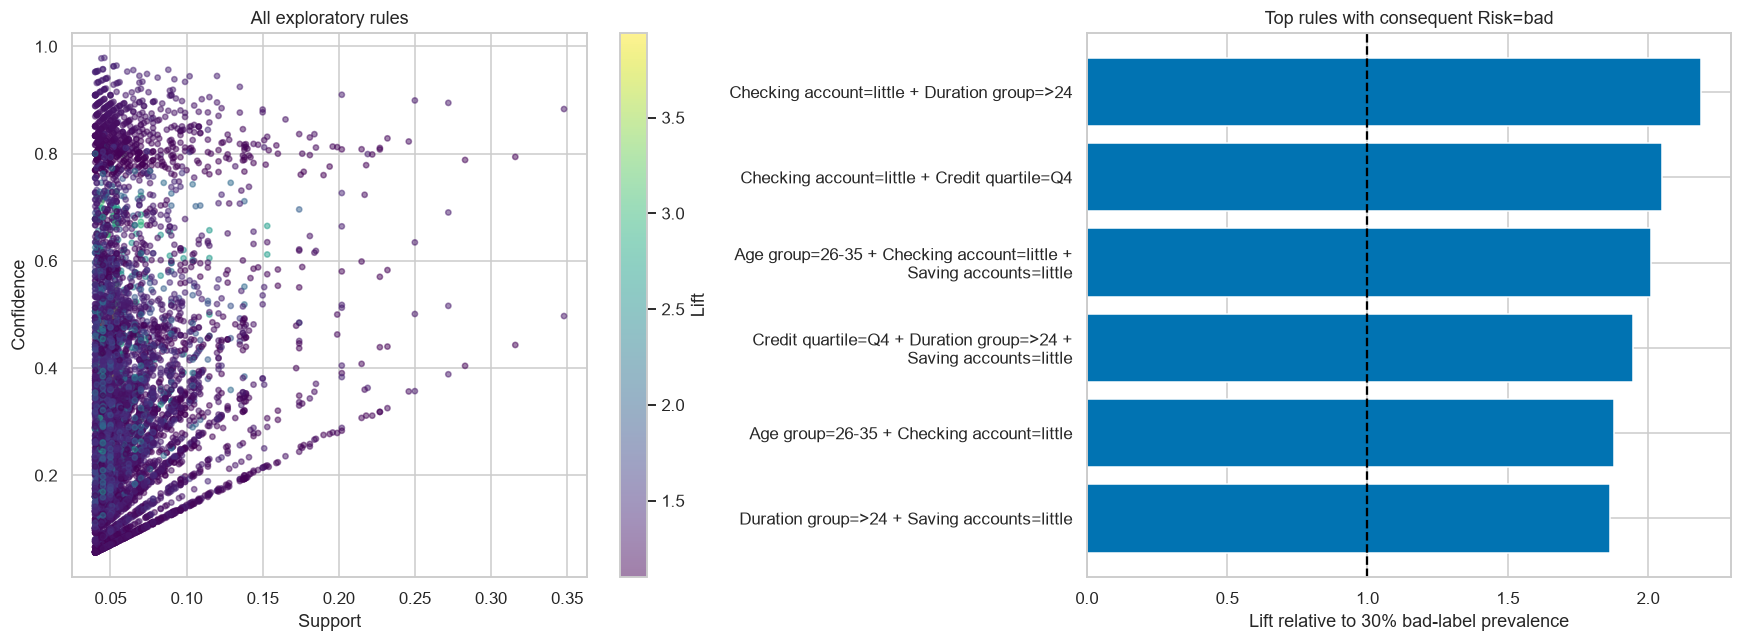

In [8]:
transactions=df[cat_cols+['Risk']].copy()
transactions['Age group']=pd.cut(df['Age'],[0,25,35,50,np.inf],labels=['<=25','26-35','36-50','>50'])
transactions['Credit quartile'],credit_edges=pd.qcut(df['Credit amount'],4,labels=['Q1','Q2','Q3','Q4'],retbins=True)
transactions['Duration group']=pd.cut(df['Duration'],[0,12,24,np.inf],labels=['<=12','13-24','>24'])
basket=pd.get_dummies(transactions,prefix_sep='=',dtype=bool)
print('Credit quartile edges (DM):',credit_edges,'; basket shape:',basket.shape)
start=time.perf_counter()
ap=apriori(basket,min_support=.04,use_colnames=True)
ap_seconds=time.perf_counter()-start
start=time.perf_counter()
fp=fpgrowth(basket,min_support=.04,use_colnames=True)
fp_seconds=time.perf_counter()-start
ap_map=dict(zip(ap['itemsets'],ap['support']))
fp_map=dict(zip(fp['itemsets'],fp['support']))
assert ap_map.keys()==fp_map.keys() and all(np.isclose(v,fp_map[k]) for k,v in ap_map.items())
rules=association_rules(ap,metric='lift',min_threshold=1.1)
bad_rules=rules[rules['consequents'].eq(frozenset({'Risk=bad'})) & rules['antecedents'].map(lambda s:not any(x.startswith('Risk=') for x in s))].copy()
bad_rules['Antecedent']=bad_rules['antecedents'].map(lambda s:' + '.join(sorted(s)))
bad_rules=bad_rules.sort_values(['lift','support','Antecedent'],ascending=[False,False,True])
bad_rules['Joint count']=(bad_rules['support']*len(df)).round().astype(int)
bad_rules['Antecedent count']=(bad_rules['antecedent support']*len(df)).round().astype(int)
rule_table=bad_rules[['Antecedent','Joint count','Antecedent count','support','confidence','lift']]
table(rule_table.head(10),'top_bad_risk_rules')
rule_table.to_csv(RESULTS/'all_bad_risk_rules.csv',index=False)
all_rules=rules.copy()
for col in ['antecedents','consequents']: all_rules[col]=all_rules[col].map(lambda s:' + '.join(sorted(s)))
all_rules.to_csv(RESULTS/'all_association_rules.csv',index=False)
print(f'Both algorithms: {len(ap)} itemsets; {len(rules)} rules. Apriori {ap_seconds:.3f}s; FP-Growth {fp_seconds:.3f}s.')
fig,axes=plt.subplots(1,2,figsize=(16,6))
sc=axes[0].scatter(rules['support'],rules['confidence'],c=rules['lift'],cmap='viridis',s=12,alpha=.5)
fig.colorbar(sc,ax=axes[0],label='Lift')
axes[0].set(xlabel='Support',ylabel='Confidence',title='All exploratory rules')
top=rule_table.head(6).iloc[::-1]
axes[1].barh([textwrap.fill(a,45) for a in top['Antecedent']],top['lift'])
axes[1].axvline(1,color='black',linestyle='--')
axes[1].set(xlabel='Lift relative to 30% bad-label prevalence',title='Top rules with consequent Risk=bad')
savefig('10_association_rules')

## 7. Ethics, recommendations, and future work
**Privacy:** The historical data contains no direct names/contact details; none were added. Demographic combinations remain potentially sensitive. Use aggregate findings and do not attempt re-identification.

**Fairness:** Age, recorded sex, housing, and job may reflect historical discrimination or selection. Removing age/sex alone would not remove proxies. The binary sex field simplifies an original combined personal-status/sex variable and does not represent all identities. This small, historical German sample cannot establish modern performance or fairness.

**Actions implemented:** Verified all label mappings; retained account-status categories; isolated preprocessing inside CV; stratified classification; reported baselines and minority-class metrics; audited errors by sex and age below. Undefined rates remain missing. Small denominators and absent uncertainty intervals limit interpretation; these checks do not certify fairness.

**Recommendations:** Use regression with its error diagnostics, particularly for large loans. Compare classifier misses and false alarms; validate calibration and explicit decision costs before operational use. Treat clusters/rules as hypotheses. The data does not justify automatic approvals, specific pricing markups, mandatory down payments, or demographic targeting.

**Future work:** Contemporary external validation, repeated/nested CV, uncertainty estimates, nonlinear regression and feature ablations, cluster stability and mixed-data distances, independent rule validation, calibration, and intersectional fairness analysis. Previously inspected benchmark test rows are not a new blind test.

,Attribute,Group,n,Actual bad,Actual good,False positive rate,Bad recall,Predicted bad rate
0,Sex,female,61,20,41,0.0244,0.4000,0.1475
1,Sex,male,139,40,99,0.0505,0.2000,0.0935
2,Age band,<=25,44,20,24,0.0417,0.3500,0.1818
3,Age band,26-35,66,21,45,0.0444,0.3333,0.1364
4,Age band,36-50,61,14,47,0.0213,0.0714,0.0328
5,Age band,>50,29,5,24,0.0833,0.2000,0.1034


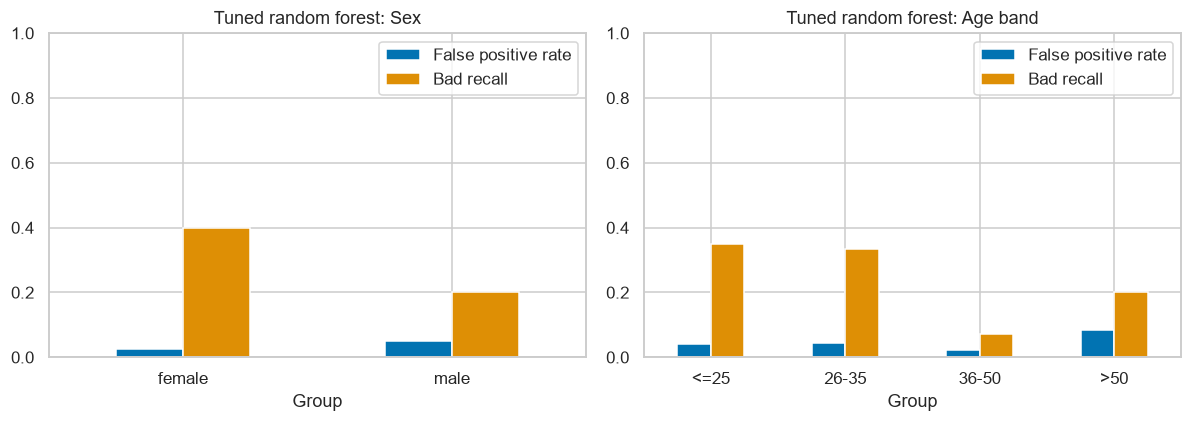

In [9]:
audit=cx_test[['Sex','Age']].copy()
audit['Actual bad']=cy_test
audit['Predicted bad']=class_predictions[selected_class]
audit['Age band']=pd.cut(audit['Age'],[0,25,35,50,np.inf],labels=['<=25','26-35','36-50','>50'])
audit_rows=[]
for attribute in ['Sex','Age band']:
    for group,sub in audit.groupby(attribute,observed=True):
        tn,fp_count,fn,tp=confusion_matrix(sub['Actual bad'],sub['Predicted bad'],labels=[0,1]).ravel()
        audit_rows.append({'Attribute':attribute,'Group':str(group),'n':len(sub),'Actual bad':int(tp+fn),'Actual good':int(tn+fp_count),
         'False positive rate':fp_count/(fp_count+tn) if fp_count+tn else np.nan,
         'Bad recall':tp/(tp+fn) if tp+fn else np.nan,'Predicted bad rate':sub['Predicted bad'].mean()})
fairness=pd.DataFrame(audit_rows)
table(fairness,'subgroup_error_audit')
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,attribute in zip(axes,['Sex','Age band']):
    fairness[fairness['Attribute'].eq(attribute)].set_index('Group')[['False positive rate','Bad recall']].plot.bar(ax=ax)
    ax.set_title(f'{selected_class}: {attribute}')
    ax.set_ylim(0,1)
    ax.tick_params(axis='x',rotation=0)
savefig('11_subgroup_error_audit')

## 8. Computed final insights
The summary below is computed from this run's results. The README summarizes the submitted findings.

In [10]:
r=reg_results.set_index('Model').loc[selected_reg]
c=class_results.set_index('Model').loc[selected_class]
best_sil=cluster_results.loc[cluster_results['Silhouette'].idxmax()]
top_rule=rule_table.iloc[0]
summary=f"""## Major findings
- **Preparation:** 1,000 applicants; nine shared attributes and all risk labels verified. Savings/checking missing counts before cleaning: {int(missing.loc['Saving accounts','Missing'])}/{int(missing.loc['Checking account','Missing'])}. Duplicates: {duplicate_count}.
- **EDA:** Mean credit amount {df['Credit amount'].mean():,.1f} DM; original/log skewness {df['Credit amount'].skew():.2f}/{np.log1p(df['Credit amount']).skew():.2f}; duration–amount correlation {correlation:.3f}.
- **Regression:** CV selected **{selected_reg}** (CV RMSE {r['CV RMSE']:,.1f} DM). Test R² **{r['Test R2']:.3f}**, RMSE **{r['Test RMSE']:,.1f} DM**, MAE {r['Test MAE']:,.1f} DM. Errors remain substantial; these are not affordability estimates.
- **Classification:** CV selected **{selected_class}** (CV AUC {c['CV AUC']:.3f}). Test AUC **{c['Test AUC']:.3f}**, accuracy {c['Accuracy']:.1%}, bad-class recall **{c['Bad recall']:.1%}**, precision {c['Bad precision']:.1%}. Compare against 70% majority accuracy; accuracy alone hides missed bad labels.
- **Clustering:** Highest silhouette **{best_sil['Silhouette']:.3f} at k={best_k}**; k=3 silhouette {cluster_results.set_index('k').loc[3,'Silhouette']:.3f}; K-Means/hierarchical ARI {ari:.3f}. Weak separation limits claims of intrinsic borrower groups.
- **Association rules:** Both algorithms return **{len(ap):,} itemsets**, yielding {len(rules):,} rules at lift ≥1.1. Top bad-label rule: `{top_rule['Antecedent']}` → `Risk=bad`, support {top_rule['support']:.1%}, confidence {top_rule['confidence']:.1%}, lift {top_rule['lift']:.3f}; {int(top_rule['Joint count'])} joint matches among {int(top_rule['Antecedent count'])} antecedent matches. This is an in-sample association.
- **Ethics:** Subgroup errors and denominators are reported; fairness, causation, and modern deployment readiness are not established.
"""
display(Markdown(summary))
(RESULTS/'summary.json').write_text(json.dumps({'selected_regression':selected_reg,'selected_classifier':selected_class,
 'best_silhouette_k':best_k,'hierarchical_ari':ari,'frequent_itemsets':len(ap),'association_rules':len(rules),
 'credit_quartile_edges':credit_edges.tolist()},indent=2))
print('Figures and result tables regenerated.')

## Major findings
- **Preparation:** 1,000 applicants; nine shared attributes and all risk labels verified. Savings/checking missing counts before cleaning: 183/394. Duplicates: 0.
- **EDA:** Mean credit amount 3,271.3 DM; original/log skewness 1.95/0.13; duration–amount correlation 0.625.
- **Regression:** CV selected **Elastic Net (original)** (CV RMSE 2,102.2 DM). Test R² **0.369**, RMSE **1,959.4 DM**, MAE 1,351.4 DM. Errors remain substantial; these are not affordability estimates.
- **Classification:** CV selected **Tuned random forest** (CV AUC 0.758). Test AUC **0.774**, accuracy 75.0%, bad-class recall **26.7%**, precision 72.7%. Compare against 70% majority accuracy; accuracy alone hides missed bad labels.
- **Clustering:** Highest silhouette **0.241 at k=2**; k=3 silhouette 0.168; K-Means/hierarchical ARI 0.408. Weak separation limits claims of intrinsic borrower groups.
- **Association rules:** Both algorithms return **1,520 itemsets**, yielding 7,796 rules at lift ≥1.1. Top bad-label rule: `Checking account=little + Duration group=>24` → `Risk=bad`, support 4.2%, confidence 65.6%, lift 2.188; 42 joint matches among 64 antecedent matches. This is an in-sample association.
- **Ethics:** Subgroup errors and denominators are reported; fairness, causation, and modern deployment readiness are not established.


Figures and result tables regenerated.


## References
Hofmann, H. (1994). *Statlog (German Credit Data)*. UCI Machine Learning Repository. [DOI: 10.24432/C5NC77](https://doi.org/10.24432/C5NC77). [UCI documentation and variable codes](https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data).

[Kaggle derivative](https://www.kaggle.com/datasets/varunchawla30/german-credit-data). The three linked project repositories supply earlier analyses and team attribution; the original repositories are linked above.